# 01　OFDM：发送与立即接收

本册把 **OFDM（1024 点 FFT，QPSK 子载波）** 的已知比特发出去再立刻整包抓回，
落成 `mod_01_OFDM.npz`。解调在 `02_OFDM_demod`，判据在 `03_OFDM_verify`。

| 项 | 值 |
|---|---|
| 网格 | N=1024，CP=128，子载波间隔 250 kHz |
| 占用 | \|k\| ∈ [8, 60]，±15 MHz；导频 14（BPSK）+ 数据 92（QPSK） |
| 帧结构 | 训练 ×2 + 数据 ×6 + 零保护 512，9728 点 / 帧 |
| 载荷 | 9 帧 × 1024 bit = 9216 bit（网格容量 1104 bit/帧） |
| 突发 | 90112 点 = 0.352 ms，峰值 0.4（−8 dBFS） |
| 硬件 | `v106/soc.bit` / RF 4096 MSPS / 字率 256 MHz / NCO 1000 MHz / 外部 SMA 环回 |

与五个单载波案例不同，OFDM 的"帧"是**时频网格**：比特先做 QPSK 映射铺到 92 个数据子载波上，
再由 IFFT 变成时域符号。接收端反过来 FFT 回频域，用训练符号估出的逐子载波信道做均衡。


## 1　导入与参数

`ofdm_dsp` 只依赖 `qpsk_dsp` 的位/字转换、突发定位与 FFT 相关，不 import pynq ——
所以解调册、校验册断电重启后也能直接跑。

`.npz` 一律落在库目录 `/home/xilinx/modulation/`，notebook 目录里只留 `.ipynb`。


In [1]:
import os
import sys

# 库目录：mod_dsp / mod_cases / ofdm_dsp / ofdm_case / 全部 .npz 都在这里
LIB  = "/home/xilinx/modulation"
QPSK = "/home/xilinx/qpsk"        # qpsk_dsp / qpsk_hw / qpsk_init / run_test
for _p in (LIB, QPSK):
    if os.path.isdir(_p) and _p not in sys.path:
        sys.path.insert(0, _p)

CASE = "OFDM"
N_TX, N_DEMOD, N_VERIFY = 1, 2, 3
# 抓包（第 N_TX 册写，第 N_DEMOD / N_VERIFY 册读）与指标（第 N_DEMOD 册写）
CAP_NPZ = os.path.join(LIB, "mod_%02d_%s.npz" % (N_TX, CASE))
DEM_NPZ = os.path.join(LIB, "mod_%02d_%s.npz" % (N_DEMOD, CASE))

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

%matplotlib inline

import mod_dsp as M
import mod_cases as C
import ofdm_dsp as O
import ofdm_case as OC

# font.family 列表触发逐字形回退（mpl≥3.6）：拉丁取自 DejaVu，中文取本机
# 已有的 CJK 字体（板上 Droid Sans Fallback / Windows 雅黑）。只列**已安装**的
# 名字，否则 matplotlib 会为每个字形打一行 findfont 警告（实测上千行）。
import matplotlib.font_manager as _fm
_avail = {f.name for f in _fm.fontManager.ttflist}
_fam = [n for n in ("DejaVu Sans", "Microsoft YaHei", "Noto Sans CJK SC",
                    "WenQuanYi Zen Hei", "Droid Sans Fallback") if n in _avail]
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 9,
    "axes.titlesize": 10, "legend.fontsize": 8,
    "font.family": _fam or ["DejaVu Sans"],
    "axes.unicode_minus": False,
})

print("ofdm_dsp :", O.__file__)
print("ofdm_case:", OC.__file__)
print("案例     : %s（OFDM，%d 子载波 / %d bit 每帧）"
      % (CASE, len(O.K_USED), O.N_BITS))
print("库目录   :", LIB)
import qpsk_dsp as D

print("qpsk_dsp :", D.__file__)
print("抓包文件 :", CAP_NPZ)


ofdm_dsp : /home/xilinx/modulation/ofdm_dsp.py
ofdm_case: /home/xilinx/modulation/ofdm_case.py
案例     : OFDM（OFDM，106 子载波 / 1024 bit 每帧）
库目录   : /home/xilinx/modulation
qpsk_dsp : /home/xilinx/qpsk/qpsk_dsp.py
抓包文件 : /home/xilinx/modulation/mod_01_OFDM.npz


## 2　生成 OFDM 基带

### 为什么这样铺网格

- **只占 ±15 MHz**：IFFT 的 1024 根栅格里只用 106 根（\|k\| ∈ [8, 60]）。带外留空有两个好处：
  DAC 插值滤波器与模拟通道在 ±15 MHz 内足够平坦，不会把边带削出滚降；同时避开 ADC 直流附近的
  泄漏（\|k\| < 8 也留空）。
- **训练符号重复两次**：两个相同的训练符号给出定时相关峰、CFO（两段之间的相位差）和逐子载波
  LS 信道估计；一个符号只能量到混叠后的 \|Δf\|。
- **导频每 8 根放一个**：BPSK 已知符号，接收端用它们的相位均值估公共相位（残余 CFO / 相位噪声），
  每个数据符号单独纠一次。
- **峰值 0.4**：OFDM 的 PAPR 约 19.5 dB，峰值 0.4 时 rms 只有 0.042（≈1390 LSB），
  16 bit 量化噪声完全可忽略；再往上抬峰值只会先削顶。

每帧 1024 bit 装进 1104 bit 的网格容量，尾部补 0（补的 0 不计入 BER）。


In [2]:
const, payload, bb, meta = OC.build()
words = D.to_words(bb)

peak_lsb = int(np.max(np.abs(bb)) * 32767)
clip     = int(np.sum(np.abs(bb) * 32767 >= 32767))
print("案例 %s：%d 帧 × %d bit = %d bit，突发 %d 点 = %.3f ms"
      % (CASE, meta["frames"], meta["n_bits"],
         meta["frames"] * meta["n_bits"], len(bb), len(bb) / 256e6 * 1e3))
print("每帧 %d 点（训练 %d + 数据 %d×%d + 保护 %d），PAPR %.1f dB"
      % (meta["frame_len"], O.TRAIN_LEN, meta["n_sym"], O.SYM_LEN, O.GUARD,
         meta["papr_db"]))
print("峰值 %d LSB（%.0f%% 满量程），削顶 %d 点（必须为 0），字 %d 个"
      % (peak_lsb, 100 * meta["peak"], clip, len(words)))


案例 OFDM：9 帧 × 1024 bit = 9216 bit，突发 90112 点 = 0.352 ms
每帧 9728 点（训练 2304 + 数据 6×1152 + 保护 512），PAPR 19.5 dB
峰值 13106 LSB（40% 满量程），削顶 0 点（必须为 0），字 90112 个


**应该看到**：`9 帧 × 1024 bit = 9216 bit`、`90112 点 = 0.352 ms`、
`PAPR 19.5 dB`、峰值 `13106 LSB`、削顶 `0` 点。


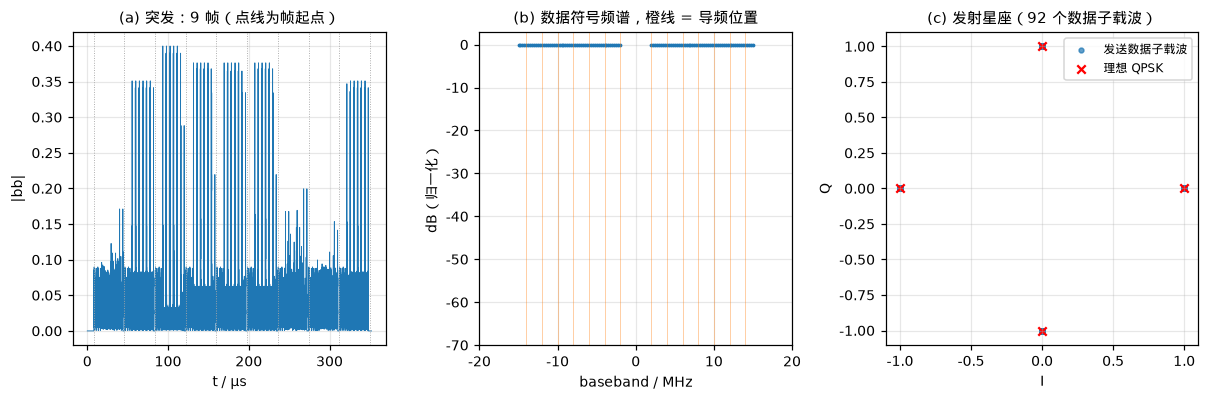

In [3]:
fig = plt.figure(figsize=(13.2, 3.7))
gs = fig.add_gridspec(1, 3, wspace=0.30)

ax = fig.add_subplot(gs[0, 0])
t = np.arange(len(bb)) / 256e6 * 1e6
ax.plot(t, np.abs(bb), lw=0.6)
for i in range(meta["frames"] + 1):
    x0 = (meta["lead"] + i * meta["frame_len"]) / 256e6 * 1e6
    ax.axvline(x0, color="0.65", ls=":", lw=0.6)
ax.set_xlabel("t / µs"); ax.set_ylabel("|bb|")
ax.set_title("(a) 突发：%d 帧（点线为帧起点）" % meta["frames"])

ax = fig.add_subplot(gs[0, 1])
lead = meta["lead"]; s0 = 3
st = lead + O.TRAIN_LEN + s0 * O.SYM_LEN + O.CP
X = np.fft.fftshift(np.fft.fft(bb[st:st + O.N]))
f = np.fft.fftshift(np.fft.fftfreq(O.N, 1 / 256e6))
dB = 20 * np.log10(np.abs(X) + 1e-12)
ax.plot(f / 1e6, dB - dB.max(), ".", ms=3)
for k in O.K_PILOT:
    ax.axvline(k * O.SPACING / 1e6, color="C1", lw=0.4, alpha=0.6)
ax.set_xlim(-20, 20); ax.set_ylim(-70, 3)
ax.set_xlabel("baseband / MHz"); ax.set_ylabel("dB（归一化）")
ax.set_title("(b) 数据符号频谱，橙线 = 导频位置")

ax = fig.add_subplot(gs[0, 2])
Ytx = np.fft.fft(bb[st:st + O.N])[O.K_DATA % O.N]
Ytx = Ytx / np.mean(np.abs(Ytx))       # 突发按峰值归一化过，这里按平均幅度归一
ax.scatter(Ytx.real, Ytx.imag, s=10, alpha=0.7, label="发送数据子载波")
ph = np.pi / 2 * np.arange(4)          # 0° / 90° / 180° / 270°
ax.scatter(np.cos(ph), np.sin(ph), s=30, marker="x", color="r",
           label="理想 QPSK")
ax.set_xlabel("I"); ax.set_ylabel("Q"); ax.set_aspect("equal")
ax.set_title("(c) 发射星座（%d 个数据子载波）" % len(O.K_DATA))
ax.legend(loc="upper right")
plt.show()


**应该看到**：9 段等长的帧包络；(b) 是 106 根梳状谱线，其中 14 根（橙线）是导频；
(c) 四个点严格落在 $\pm1$、$\pm j$ 上（QPSK 相位 0°/90°/180°/270°），无扩散。

发射侧没有脉冲成型（OFDM 的频谱形状由 IFFT 栅格决定），所以旁瓣比单载波 QPSK 的 RRC 低得多，
带外只是矩形窗泄漏。这是 OFDM 的常态，不是"没成型"。


## 3　环境就绪：时钟、位流、RFDC、DMA

与 `00_OFDM_init` 做的是同一件事，直接复用 —— **01 跑过时这里只承接（约 2 s）**，断电重启后它也会把整条链自建一遍：

| 动作 | 函数 | 说明 |
|---|---|---|
| LMK 256 MHz + SYSREF | `qpsk_init.ensure_clock()` | 已锁定时 ~0.2 s 返回，不重写寄存器 |
| 位流 `v106/soc.bit` | `run_test.open_clean_loopback()` | PL 里已是 v106 就只解析 hwh，不重下 |
| RFDC 4096 MSPS + NCO 1000 MHz | 同上 | 同进程内已 init 过就不再 StartUp |
| 环回自检 | 同上 | 打一发 QPSK 探针，波峰因数 < 2.5 才算干净 |

**为什么用 QPSK 探针而不是 OFDM**：波峰因数判据只对包络近似恒定的单载波成立；
OFDM 的 PAPR 约 19.5 dB，用同一阈值会一直误报。OFDM 的链路质量由 02 的 EVM / BER 直接判。


In [4]:
import time

import qpsk_init as QI
import run_test as R

clk = QI.ensure_clock()

probe = C.build_payload_set(1024, 9, 300)
h_q = D.rrc_filter(D.SPS)
probe_bb, _, _ = D.build_burst([b for _t, b in probe], h_q, D.SPS, peak=C.PEAK)

t_open = time.time()
lb, n_try, cf = R.open_clean_loopback(D.to_words(probe_bb), len(probe_bb))
print()
print("环回就绪：自检 %d 次，波峰因数 %.2f（阈值 %.1f），耗时 %.1f s"
      % (n_try, cf, R.CF_CLEAN, time.time() - t_open))
print("字率 %.3f MHz，RF %.1f MSPS" % (lb.fs_word / 1e6, lb.fs_rf))
st = lb.status()
for k in ("DAC", "ADC"):
    v = st[k]
    print("%s0 : enabled=%s  state=0x%X  PLL=%s"
          % (k, v.get("enabled"), v.get("state", 0), v.get("pll")))


  读回窗口自检通过（3 字节传输，rx[2] = 数据字节）

=== 配置四线 SPI readback ===
  SPI_LOCK 解锁 (R0x1FFD/R0x1FFE=0x00, R0x1FFF=0x53)
  R0x000 = 0x10 (SPI_3WIRE_DIS=1)
  R0x15F 无条件写回 0x13（写前读到 0x13，脏状态下该读数不可信）
  R0x16E = 0x3B (PLL2_LD_MUX=7 readback, TYPE=3 推挽)
  读回可信度检查通过（R0x171=0xAA / R0x172=0x02）
→ PLL2 已锁定、SYSREF 连续输出，跳过写表
  LMK 现状: 读回可信=True  PLL1 LD=0(0x00)  PLL2 LD=1(0x02)  SYSREF MUX=3
  [PASS] LMK 读回可信                                 R0x171=0xAA / R0x172=0x02
  [PASS] LMK PLL2 锁定（RFDC 时钟源）                 R0x183=0x02
  [PASS] SYSREF 连续输出（MUX=3）                     R0x139 MUX=3
  PLL1 LD=0（本板 PLL1 空载，LD=0 正常，不是故障）

 2　时钟
  结果  项目                                         实测 / 说明
  ----------------------------------------------------------------------------
  PASS  LMK 读回可信                                 R0x171=0xAA / R0x172=0x02
  PASS  LMK PLL2 锁定（RFDC 时钟源）                 R0x183=0x02
  PASS  SYSREF 连续输出（MUX=3）                     R0x139 MUX=3
  --------------------------------------------------------

  overlay 承接 1051 ms，5 个 IP
  DAC0 NCO 已是 1000.000 MHz，沿用
  ADC0 NCO 已是 1000.000 MHz，沿用


  环回自检  0（首次建立）：波峰因数 1.66  OK

环回就绪：自检 1 次，波峰因数 1.66（阈值 2.5），耗时 2.4 s
字率 256.000 MHz，RF 4096.0 MSPS
DAC0 : enabled=True  state=0xF  PLL=1
ADC0 : enabled=True  state=0xF  PLL=1


**应该看到**：`PLL2 LD=1`、`SYSREF MUX=3`、`波峰因数 < 2.5`、`DAC0 state=0xF`、`ADC0 enabled=1`。

**不对怎么查**：

| 现象 | 处置 |
|---|---|
| `PLL2 LD=0` | `QI.ensure_clock(force=True)` 重写 LMK 表 |
| 波峰因数 ≥ 3 | ADC 只回了 I 通道；`open_clean_loopback` 会自动 `rf_reinit()`，连续失败再查环回线 |
| `DAC state≠0xF` | 回 `00_OFDM_init` 第 4 节（RFDC 与 NCO） |


## 4　收发并落盘

时序与 `qpsk/01_qpsk_tx_rx` 一致：**先挂接收、再启动发送**，这样突发完整落在 16.38 ms 的接收窗里。
一次 `lb.loop(words)` 同时完成 MM2S 发送与 S2MM 整包接收。

落盘存突发前后各 64k 点的一段（整包 4.19 M 字里 99% 是静默），存的是**原始字**，
`02_OFDM_demod` 可以据此把接收机每一步重算一遍。真值比特随抓包一起存进 `.npz`，
02/03 不需要重放随机数就能知道每帧发了什么。


In [5]:
t0 = time.time()
G = lb.loop(words)
dt = time.time() - t0

x = D.from_words(G["w"])
n = int(G["n"])
x = x[:n] if n else x
a, e = D.find_active(x)

OC.save(CAP_NPZ, x, len(bb), lb.fs_word, payload,
        extra=dict(papr_db=meta["papr_db"]))

rms = float(np.sqrt(np.mean(np.abs(x[a:e]) ** 2)))
print("%s 收 %d 字（%.2f ms）  活跃区 [%d, %d) 长度 %d  段内 rms %.0f LSB"
      % (CASE, n, n / lb.fs_word * 1e3, a, e, e - a, rms))
print("TX %s  GAP %.0f µs  墙钟 %.0f ms"
      % ("完成" if G["tx_ok"] else "未完成", G["gap_us"], dt * 1e3))
print("已存 %s（%.2f MB）" % (CAP_NPZ, os.path.getsize(CAP_NPZ) / 1e6))


OFDM 收 4194299 字（16.38 ms）  活跃区 [20480, 110592) 长度 90112  段内 rms 554 LSB
TX 完成  GAP 77 µs  墙钟 263 ms
已存 /home/xilinx/modulation/mod_01_OFDM.npz（0.44 MB）


**应该看到**：`TX 完成`，GAP 几十 µs，接收 4 194 303 字（≈16.38 ms），
活跃区 90112 点（0.352 ms 突发），段内 rms 约 550 LSB（环回衰减约 8 dB）。

rms 远小于峰值是 OFDM 的正常形态（PAPR 19.5 dB，峰值/rms ≈ 9.4）。若 rms 低于 200 LSB，
检查 `PEAK` 是否被改小或环回衰减器是否换了；若活跃区长度远大于 90k，说明环回里串进了别的信号。


## 5　小结

下一册 `02_OFDM_demod` 只读这个 `.npz`，不碰硬件。


In [6]:
p = CAP_NPZ
print("%-6s %-6s %10s  %s" % ("案例", "类型", "文件 MB", "文件"))
print("-" * 78)
print("%-6s %-6s %10.2f  %s"
      % (CASE, "OFDM", os.path.getsize(p) / 1e6, p))
print()
print("下一步：打开 %02d_%s_demod.ipynb（解调）→ %02d_%s_verify.ipynb（判定）"
      % (N_DEMOD, CASE, N_VERIFY, CASE))


案例     类型          文件 MB  文件
------------------------------------------------------------------------------
OFDM   OFDM         0.44  /home/xilinx/modulation/mod_01_OFDM.npz

下一步：打开 02_OFDM_demod.ipynb（解调）→ 03_OFDM_verify.ipynb（判定）
